# 02d · County Categorical Features

Adds static county features, mostly categorical (the rubric requires ≥4 categorical variables), that bear on lanternfly survival and spread:

| Feature | Type | Source | Why it might matter |
|---|---|---|---|
| `census_division` | categorical (9) | Census | Broad geography / distance from the PA introduction |
| `rucc_2023`, `metro` | ordinal (1–9), binary | USDA ERS Rural-Urban Continuum Codes 2023 | Urban areas: more Tree of Heaven, more freight, more observers |
| `ecoregion_l3`, `ecoregion_l1` | categorical (85 / 10) | EPA Level III ecoregions, largest share of county area | Habitat type beyond climate |
| `has_interstate`, `interstate_km_per_km2` | binary, numeric | Census TIGER 2023 primary roads (interstates) | Egg masses travel on vehicles |
| `has_rail`, `rail_km_per_km2` | binary, numeric | Census TIGER 2023 rail (main lines) | Rail cars are a known spread pathway |
| `pop_2020`, `pop_density_km2` | numeric | USDA ERS (Census 2020) | Introduction pressure; also tied to observer effort |

**Connecticut:** the 2023 codes use CT's new planning regions, so its 8 counties take their codes from the 2013 edition (population 2010); see `rucc_source`.

> **AI-generated code (Claude Code).** See `docs/ai_usage.md`. *Team interpretation* cells are for the team to write.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import kruskal, spearmanr

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
import data_sources as ds

feat = ds.load_county_features()
print(feat.shape)
feat.head()

(3108, 18)


,fips,state,county,land_km2,census_division,rucc_2023,metro,pop_2020,rucc_source,pop_density_km2,ecoregion_l3,ecoregion_l1,interstate_km,rail_km,interstate_km_per_km2,rail_km_per_km2,has_interstate,has_rail
0,01061,AL,Geneva,1487.908432,East South Central,3,Metro,26659,2023,17.917097,Southeastern Plains,EASTERN TEMPERATE FORESTS,0.000000,0.000000,0.00000,0.000000,False,False
1,08125,CO,Yuma,6123.763559,Mountain,9,Nonmetro,9988,2023,1.631023,High Plains,GREAT PLAINS,0.000000,78.085711,0.00000,0.012751,False,True
2,17177,IL,Stephenson,1461.392061,East North Central,4,Nonmetro,44630,2023,30.539375,Central Corn Belt Plains,EASTERN TEMPERATE FORESTS,0.000000,54.520459,0.00000,0.037307,False,True
3,28153,MS,Wayne,2099.745602,East South Central,9,Nonmetro,19779,2023,9.419713,Southeastern Plains,EASTERN TEMPERATE FORESTS,0.000000,33.420481,0.00000,0.015916,False,True
4,34041,NJ,Warren,923.435921,Middle Atlantic,2,Metro,109632,2023,118.721827,Ridge and Valley,EASTERN TEMPERATE FORESTS,94.670267,86.973850,0.10252,0.094185,True,True


## 1. What the features look like

In [2]:
for col in ["census_division", "metro", "rucc_2023", "ecoregion_l1", "has_interstate", "has_rail"]:
    print(f"\n{col}  ({feat[col].nunique()} levels)")
    print(feat[col].value_counts().to_string())
print(f"\necoregion_l3: {feat['ecoregion_l3'].nunique()} levels")
feat[["pop_density_km2", "interstate_km_per_km2", "rail_km_per_km2"]].describe().round(3)


census_division  (9 levels)
census_division
West North Central    618
South Atlantic        588
West South Central    470
East North Central    437
East South Central    364
Mountain              281
Middle Atlantic       150
Pacific               133
New England            67

metro  (2 levels)
metro
Nonmetro    1928
Metro       1180

rucc_2023  (9 levels)
rucc_2023
9    569
8    465
1    443
2    382
6    379
3    355
7    242
4    200
5     73

ecoregion_l1  (10 levels)
ecoregion_l1
EASTERN TEMPERATE FORESTS          1789
GREAT PLAINS                        839
NORTH AMERICAN DESERTS              146
NORTHERN FORESTS                    132
NORTHWESTERN FORESTED MOUNTAINS     129
MEDITERRANEAN CALIFORNIA             34
MARINE WEST COAST FOREST             26
TEMPERATE SIERRAS                     5
TROPICAL WET FORESTS                  5
SOUTHERN SEMI-ARID HIGHLANDS          3

has_interstate  (2 levels)
has_interstate
False    1686
True     1422

has_rail  (2 levels)
has_rail
True  

,pop_density_km2,interstate_km_per_km2,rail_km_per_km2
count,3108.000,3108.000,3108.000
mean,108.125,0.033,0.061
std,724.406,0.068,0.096
min,0.037,0.000,0.000
25%,6.549,0.000,0.018
50%,17.416,0.000,0.039
75%,46.030,0.048,0.072
max,28872.984,1.536,2.200


## 2. Lanternfly rate by category (invasion region)

Same subset as notebook 02c: counties in states with ≥100 lanternfly observations and ≥500 total iNaturalist observations over 2014–2025, so rates aren't dominated by tiny denominators.

**Kruskal-Wallis** tests whether the groups' distributions differ (a rank-based ANOVA; no normality assumption). A small p-value says the groups differ, not why: urban counties also have more observers, and geography overlaps every feature.

In [3]:
cy = pd.read_parquet(ds.PROCESSED / "county_year_effort.parquet")
tot = cy.groupby("fips")[["all_obs", "slf_obs"]].sum().reset_index()
d = feat.merge(tot, on="fips", how="left")
state_slf = d.groupby("state")["slf_obs"].sum()
inv = d[d["state"].isin(state_slf[state_slf >= 100].index) & (d["all_obs"] >= 500)].copy()
inv["slf_per_10k"] = 1e4 * inv["slf_obs"] / inv["all_obs"]
inv["rucc_group"] = pd.cut(inv["rucc_2023"].astype(float), [0, 1, 3, 6, 9],
                           labels=["1 large metro", "2–3 smaller metro", "4–6 nonmetro urban", "7–9 rural"])
print(f"{len(inv):,} counties in {inv['state'].nunique()} states")

rows = []
for col in ["metro", "rucc_group", "census_division", "ecoregion_l1", "has_interstate", "has_rail"]:
    groups = [g["slf_per_10k"].to_numpy() for _, g in inv.groupby(col, observed=True) if len(g) >= 5]
    h, p = kruskal(*groups)
    rows.append({"feature": col, "groups (n≥5)": len(groups), "H": h, "p_value": p})
pd.DataFrame(rows).round(4)

560 counties in 13 states


,feature,groups (n≥5),H,p_value
0,metro,2,72.5126,0.0000
1,rucc_group,4,77.2924,0.0000
2,census_division,4,64.0364,0.0000
3,ecoregion_l1,2,0.4764,0.4901
4,has_interstate,2,31.4214,0.0000
5,has_rail,2,5.0243,0.0250


**Note:** inside the invasion region almost every county falls in one Level I ecoregion (Eastern Temperate Forests), so `ecoregion_l1` has only 2 testable groups and can't separate counties here. Level III (85 regions nationally) is the usable version.

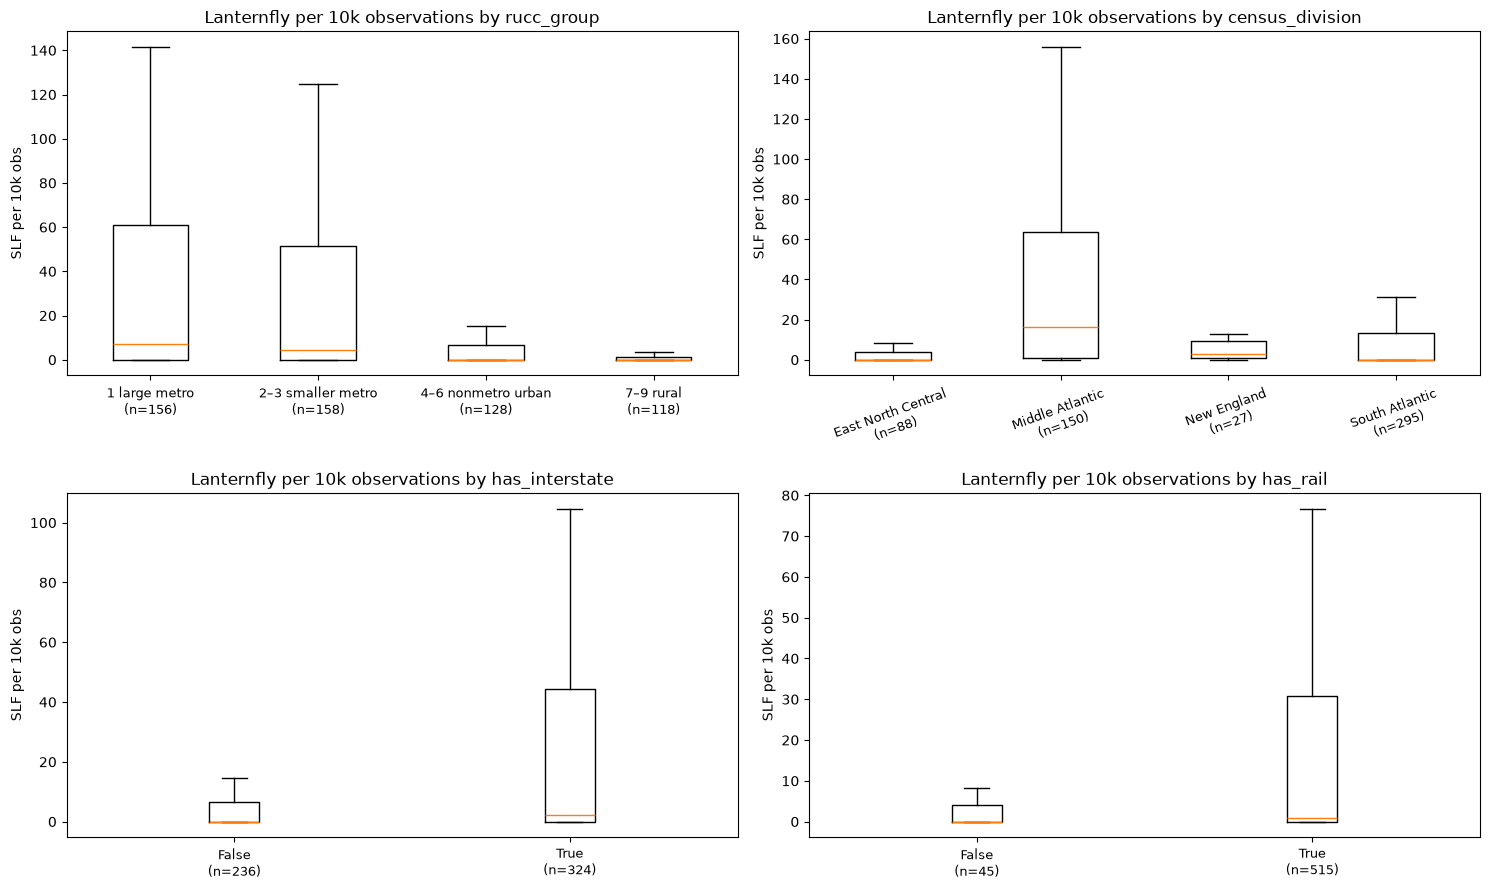

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))
for ax, col in zip(axes.flat, ["rucc_group", "census_division", "has_interstate", "has_rail"]):
    order = [k for k, g in inv.groupby(col, observed=True) if len(g) >= 5]
    groups = [inv.loc[inv[col] == k, "slf_per_10k"] for k in order]
    ax.boxplot(groups, tick_labels=[f"{k}\n(n={len(g)})" for k, g in zip(order, groups)], showfliers=False)
    ax.set(title=f"Lanternfly per 10k observations by {col}", ylabel="SLF per 10k obs")
    ax.tick_params(axis="x", labelsize=9, rotation=20 if col == "census_division" else 0)
plt.tight_layout()

## 3. Numeric transport and population features

In [5]:
rows = []
for col in ["pop_density_km2", "interstate_km_per_km2", "rail_km_per_km2"]:
    r, p = spearmanr(inv[col].to_numpy(float), inv["slf_per_10k"].to_numpy(float))
    r_eff, _ = spearmanr(inv[col].to_numpy(float), inv["all_obs"].to_numpy(float))
    rows.append({"feature": col, "rho_vs_slf_rate": r, "p_value": p, "rho_vs_effort": r_eff})
pd.DataFrame(rows).round(3)

,feature,rho_vs_slf_rate,p_value,rho_vs_effort
0,pop_density_km2,0.464,0.0,0.531
1,interstate_km_per_km2,0.330,0.0,0.418
2,rail_km_per_km2,0.395,0.0,0.259


`rho_vs_effort` shows how strongly each feature tracks observer effort. Features that track effort closely (population density especially) need care in the model, because effort is already a predictor.

### Team interpretation
_To be written by the team. Prompts:_
- Which categories show the clearest differences in lanternfly rate? Are they plausibly about lanternflies, or about observers?
- Ecoregion L3 has 85 levels: use L1 (10), group L3, or target-encode?
- **Decision:** which ≥4 categorical features go into the model?